# Practical 4: Classification with Lazy and Probabilistic Learning
**Project:** Groundwater Level Prediction & Risk Classification

**Input file:** `03_wells_with_risk.csv` (saved by Practical 3)
**Output file:** `05_knn_nb_results.csv` (used by Practical 5)

**Aim:** predict each well's 2022 risk class (Safe / Watch / Critical / Severe) using **K-Nearest Neighbors** (a lazy learner) and **Naive Bayes** (a probabilistic learner), and judge them with accuracy, precision, recall, F1, log loss, AUC and the confusion matrix.

## Step 1: Load the data and use the saved train/test split
**What to say:** *The file has a 'set' column from Practical 3, so every model is trained on the same 80% of wells and tested on the same hidden 20%. This keeps the comparison fair.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("03_wells_with_risk.csv")

features = ["Latitude", "Longitude", "Well_Depth (meters)", "pre_mean", "post_mean", "recharge", "change", "Pre_2021"]
labels = ["Safe", "Watch", "Critical", "Severe"]          # risk codes 0, 1, 2, 3

train = df[df["set"] == "train"]
test = df[df["set"] == "test"]

X_train, X_test = train[features], test[features]
y_train, y_test = train["risk_code"], test["risk_code"]

print("Training wells:", len(train), "| Test wells:", len(test))
print(y_train.value_counts().sort_index().rename(dict(enumerate(labels))))

Training wells: 1478 | Test wells: 370
risk_code
Safe        584
Watch       329
Critical    242
Severe      323
Name: count, dtype: int64


## Step 2: Scale the features
**What to say:** *KNN works with distances, so a feature with big numbers (like depth) would dominate a small one (like latitude). Scaling puts all features on the same scale. I fit the scaler on the training wells only, so no test information leaks in. Naive Bayes does not need scaling.*

In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Step 3: Set the baseline to beat
**What to say:** *A very simple rule: use last year's (2021) depth with the same depth bands as the risk classes. If a model cannot beat this rule, it adds nothing.*

In [3]:
def band(depth):
    if depth > 40:
        return 3
    elif depth > 20:
        return 2
    elif depth > 10:
        return 1
    else:
        return 0

baseline_pred = test["Pre_2021"].apply(band)
print("Baseline accuracy:", round((baseline_pred == y_test).mean(), 3))

Baseline accuracy: 0.897


## Step 4: One function to evaluate every model
**What to say:** *One function calculates all the measures, so every model is judged in exactly the same way.*

- **Accuracy:** share of wells classified correctly
- **Precision:** when the model names a class, how often it is right
- **Recall:** of the wells truly in a class, how many the model finds
- **F1:** a balance of precision and recall
- **Log loss:** punishes confident wrong answers (lower is better)
- **AUC:** how well the model ranks the classes (1 is perfect, 0.5 is random guessing)
- **At-risk recall:** of the truly Critical or Severe wells, how many were caught. This is the most important number for this project, because missing a dangerous well is worse than a false alarm.

Precision, recall and F1 are averaged over the four classes.

In [4]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, roc_auc_score, ConfusionMatrixDisplay)

results = []
predictions = {}

def evaluate(name, pred, proba=None):
    row = {"Model": name,
           "Accuracy": accuracy_score(y_test, pred),
           "Precision": precision_score(y_test, pred, average="macro"),
           "Recall": recall_score(y_test, pred, average="macro"),
           "F1": f1_score(y_test, pred, average="macro"),
           "At-risk recall": recall_score(y_test >= 2, pred >= 2)}
    if proba is not None:
        row["Log loss"] = log_loss(y_test, proba)
        row["AUC"] = roc_auc_score(y_test, proba, multi_class="ovr")
    results.append(row)
    predictions[name] = pred

evaluate("Baseline (2021 rule)", baseline_pred)

## Step 5: K-Nearest Neighbors (KNN)
**What to say:** *KNN is a lazy learner: it does not build a model in advance. To classify a new well, it finds the k most similar wells in the training data and takes a vote. The number k matters, so I tried several values using cross-validation on the training data only (the test wells stay hidden), and chose the best.*

Best k: 15


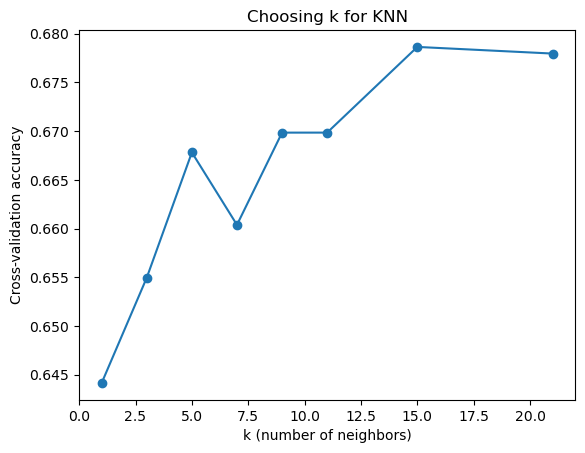

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
cv_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    cv_scores.append(cross_val_score(knn, X_train_s, y_train, cv=5).mean())

best_k = k_values[int(np.argmax(cv_scores))]
print("Best k:", best_k)

plt.plot(k_values, cv_scores, marker="o")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Cross-validation accuracy")
plt.title("Choosing k for KNN")
plt.show()

In [6]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s, y_train)

evaluate("KNN", knn.predict(X_test_s), knn.predict_proba(X_test_s))
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,At-risk recall,Log loss,AUC
0,Baseline (2021 rule),0.897,0.900,0.905,0.902,0.979,NaN,NaN
1,KNN,0.805,0.806,0.781,0.792,0.901,0.773,0.952


## Step 6: Naive Bayes
**What to say:** *Naive Bayes is a probabilistic learner. For each class it asks: how likely are these feature values if the well belongs to that class? Then it picks the most probable class. It is 'naive' because it assumes the features are independent of each other. Let me check whether that is true here.*

In [7]:
# Are the features independent? Check two of them.
print("Correlation between pre_mean and Pre_2021:", round(train["pre_mean"].corr(train["Pre_2021"]), 2))
print("Correlation between pre_mean and post_mean:", round(train["pre_mean"].corr(train["post_mean"]), 2))

Correlation between pre_mean and Pre_2021: 0.99
Correlation between pre_mean and post_mean: 1.0


**What to say:** *The features are almost perfectly correlated, so the independence assumption is clearly broken. I expect Naive Bayes to be weaker than a model that can handle related features.*

In [8]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)

evaluate("Naive Bayes", nb.predict(X_test), nb.predict_proba(X_test))

## Step 7: Compare the models and save
**What to say:** *All numbers are on test wells the models never saw. I compare both models against the baseline, and focus on at-risk recall and F1.*

In [9]:
results_table = pd.DataFrame(results).round(3)
print(results_table.to_string(index=False))

results_table.to_csv("05_knn_nb_results.csv", index=False)
print("Saved 05_knn_nb_results.csv")

               Model  Accuracy  Precision  Recall    F1  At-risk recall  Log loss   AUC
Baseline (2021 rule)     0.897      0.900   0.905 0.902           0.979       NaN   NaN
                 KNN     0.805      0.806   0.781 0.792           0.901     0.773 0.952
         Naive Bayes     0.824      0.819   0.814 0.812           0.950     0.827 0.969
Saved 05_knn_nb_results.csv


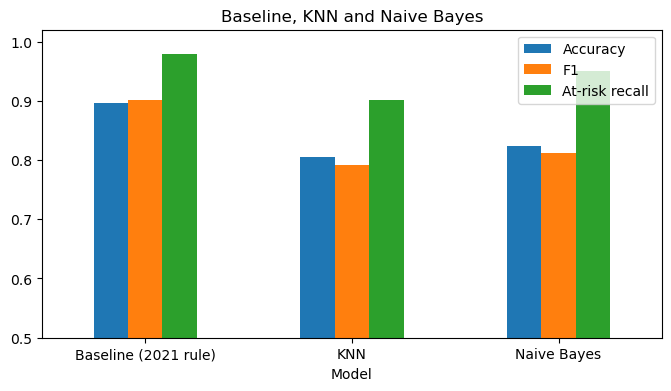

In [10]:
results_table.plot(x="Model", y=["Accuracy", "F1", "At-risk recall"], kind="bar", figsize=(8, 4))
plt.ylim(0.5, 1.02)
plt.xticks(rotation=0)
plt.title("Baseline, KNN and Naive Bayes")
plt.show()

## Step 8: Confusion matrices
**What to say:** *Each row is the true class and each column is what the model predicted. Numbers on the diagonal are correct. Most mistakes sit next to the diagonal, meaning the model confuses neighbouring classes (for example Watch and Critical), not far-apart ones (Safe and Severe).*

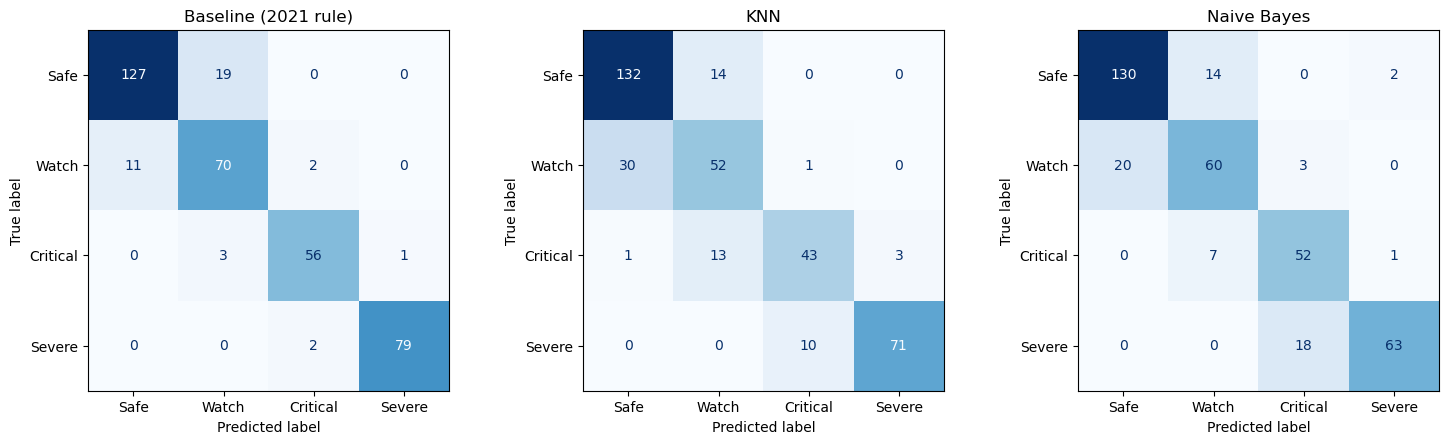

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, ["Baseline (2021 rule)", "KNN", "Naive Bayes"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], display_labels=labels,
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

---
**Next: Practical 5 (Decision Trees and SVM)**, which adds two more models and the full comparison, starting from `03_wells_with_risk.csv` and `05_knn_nb_results.csv`.